# Tugas Praktikum JS05 - Dataset PBL
## Clustering Hierarki Teks Berita Hoaks Menggunakan HDBSCAN


### 1. Load dataset PBL


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('data/pbl_hoaks_valid_clean.csv')
print('Dimensi data:', df.shape)
df.head()


Dimensi data: (1498, 2)


,teks_bersih,label
0,presiden prabowo minta maaf ikut bop akan kemb...,1
1,video presiden prabowo akan membagikan bantuan...,1
2,pemerintah kota tangerang selatan akan legalka...,1
3,tautan rekrutmen cpns kementerian imigrasi,1
4,ramuan rebusan jahe kunyit kencur dan serai be...,1


### 2. Ekstraksi fitur TF-IDF dan reduksi dimensi TruncatedSVD


In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

tfidf = TfidfVectorizer(max_features=1000)
X_tfidf = tfidf.fit_transform(df['teks_bersih'])

svd = TruncatedSVD(n_components=20, random_state=42)
X_dense = svd.fit_transform(X_tfidf)
y = df['label'].values

print('Dimensi fitur SVD:', X_dense.shape)


Dimensi fitur SVD: (1498, 20)


### 3. Clustering teks dengan HDBSCAN


In [3]:
from sklearn.cluster import HDBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

hdb = HDBSCAN(min_cluster_size=15, min_samples=5)
labels_hdb = hdb.fit_predict(X_dense)

n_clusters = len(set(labels_hdb)) - (1 if -1 in labels_hdb else 0)
n_noise = (labels_hdb == -1).sum()

print(f'Jumlah cluster terbentuk: {n_clusters}')
print(f'Jumlah noise / outlier  : {n_noise} ({n_noise / len(labels_hdb) * 100:.2f}%)')

if n_clusters > 1:
    mask = labels_hdb != -1
    if len(set(labels_hdb[mask])) > 1:
        sil = silhouette_score(X_dense[mask], labels_hdb[mask])
        dbi = davies_bouldin_score(X_dense[mask], labels_hdb[mask])
        print(f'Silhouette Score (tanpa noise): {sil:.4f}')
        print(f'Davies-Bouldin Index (tanpa noise): {dbi:.4f}')


Jumlah cluster terbentuk: 6
Jumlah noise / outlier  : 614 (40.99%)
Silhouette Score (tanpa noise): 0.4521
Davies-Bouldin Index (tanpa noise): 0.6611


C:\Users\azure\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


### 4. Visualisasi hasil clustering HDBSCAN


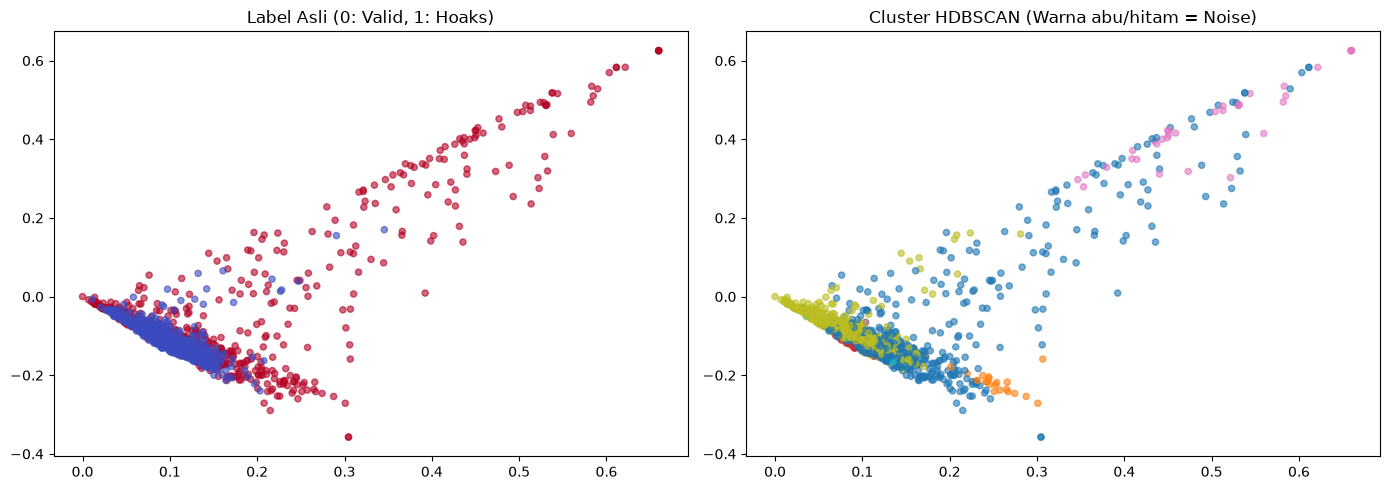

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X_dense[:, 0], X_dense[:, 1], c=y, cmap='coolwarm', alpha=0.6, s=20)
axes[0].set_title('Label Asli (0: Valid, 1: Hoaks)')

scatter = axes[1].scatter(X_dense[:, 0], X_dense[:, 1], c=labels_hdb, cmap='tab10', alpha=0.6, s=20)
axes[1].set_title('Cluster HDBSCAN (Warna abu/hitam = Noise)')

plt.tight_layout()
plt.show()
